In [26]:
import pyodbc
import pandas as pd

# ✅ Connexion SQL Server
conn_str = (
    "Driver={ODBC Driver 17 for SQL Server};"
    "Server=LAPTOP-GPVK1ANC;"
    "Database=DW_SupplyChain;"
    "Trusted_Connection=yes;"
)
cnxn = pyodbc.connect(conn_str)

# ✅ Extraction 
query = """
SELECT 
    productFK,
    brandFK,
    Production_Start_Time,
    Production_End_Time,
    manufacturedate,
    expirydate,
    Dosage,
    quantityused
FROM fact_production
"""


df_test = pd.read_sql(query, cnxn)

# 👁️ Affichage pour vérifier si on a des lignes
print("✅ Aperçu des premières lignes extraites :")
display(df_test)

print("📊 Nombre de lignes extraites :", len(df_test))


✅ Aperçu des premières lignes extraites :


C:\Users\ayadi\AppData\Local\Temp\ipykernel_7368\3147805642.py:28: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_test = pd.read_sql(query, cnxn)


,productFK,brandFK,Production_Start_Time,Production_End_Time,manufacturedate,expirydate,Dosage,quantityused
0,2,15,2022032723,2022032800,2024082023,2025083023,9,9
1,2,15,2022040823,2022040806,2024082023,2025083023,9,9
2,2,15,2022050523,2022050517,2024082023,2025083023,9,9
3,2,15,2022052123,2022052119,2024082023,2025083023,9,9
4,2,15,2022070123,2022070113,2024082023,2025083023,9,9
...,...,...,...,...,...,...,...,...
33038,4665,9,2024120223,2024120209,2024100223,2025062223,5,5
33039,4665,9,2024120723,2024120712,2024100223,2025062223,5,5
33040,4665,9,2024120923,2024120911,2024100223,2025062223,5,5
33041,4665,9,2024121423,2024121416,2024100223,2025062223,5,5


📊 Nombre de lignes extraites : 33043


C:\Users\ayadi\AppData\Local\Temp\ipykernel_7368\3695548609.py:20: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df_monthly = df_test.resample('M', on='Production_Start_Time')['quantityused'].sum()




✅ Série temporelle prête (quantité utilisée mensuellement) :
Production_Start_Time
2022-01-31    9713784581141991105104759101671105211010469210...
2022-02-28    9772844571035752825971074586621421051107646978...
2022-03-31    2331096813868214425663131010713663653891019810...
2022-04-30    2410695579148595229589881691036474418917210967...
2022-05-31    9621029773631482611075255824816667103543110410...
Freq: ME, Name: quantityused, dtype: object


In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# ✅ Tronquer les dates à 8 caractères
df_test['Production_Start_Time'] = df_test['Production_Start_Time'].astype(str).str[:8]
df_test['Production_End_Time'] = df_test['Production_End_Time'].astype(str).str[:8]

# ✅ Conversion en datetime
df_test['Production_Start_Time'] = pd.to_datetime(df_test['Production_Start_Time'], format='%Y%m%d', errors='coerce')
df_test['Production_End_Time'] = pd.to_datetime(df_test['Production_End_Time'], format='%Y%m%d', errors='coerce')

# ✅ Correction : si End < Start → on échange les deux
mask_swap = df_test['Production_End_Time'] < df_test['Production_Start_Time']
df_test.loc[mask_swap, ['Production_Start_Time', 'Production_End_Time']] = df_test.loc[mask_swap, ['Production_End_Time', 'Production_Start_Time']].values

# ✅ Tri par date
df_test = df_test.sort_values('Production_Start_Time')

# ✅ Agrégation mensuelle de quantityused
df_monthly = df_test.resample('M', on='Production_Start_Time')['quantityused'].sum()

# ✅ Visualisation
plt.figure(figsize=(12, 6))
plt.plot(df_monthly.index, df_monthly.values, marker='o')
plt.title("Quantité utilisée mensuellement")
plt.xlabel("Date")
plt.ylabel("Quantité utilisée")
plt.grid(True)
plt.show()

# ✅ Affichage limité pour vérif
print("✅ Série temporelle prête (quantité utilisée mensuellement) :")
print(df_monthly.head())


C:\Users\ayadi\AppData\Local\Temp\ipykernel_7368\2470508499.py:12: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df_monthly = df_test.resample('M', on='Production_Start_Time')['quantityused'].sum()


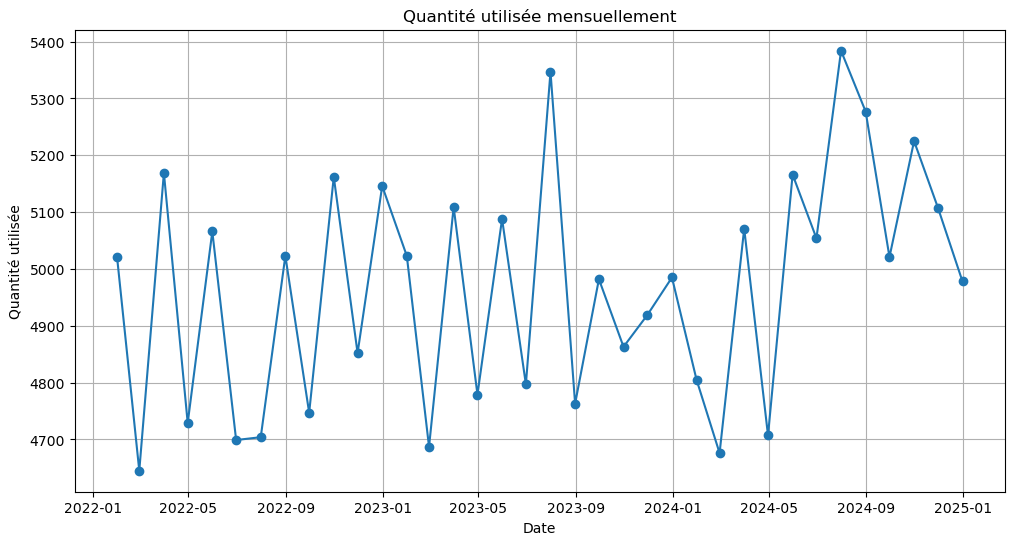

📉 Test de Dickey-Fuller Augmenté (ADF) :
Statistique ADF : -2.6560615576061837
p-value : 0.08195498857605626
Nombre de lags : 1
Nombre d'observations utilisées : 34
Valeurs critiques :
   1% : -3.639224104416853
   5% : -2.9512301791166293
   10% : -2.614446989619377
❌ La série n'est PAS stationnaire (on ne rejette pas H0).


In [32]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# ✅ Conversion correcte de la colonne quantityused avant toute opération
df_test['quantityused'] = pd.to_numeric(df_test['quantityused'], errors='coerce')

# ✅ Supprimer les lignes avec valeurs manquantes
df_test = df_test.dropna(subset=['quantityused'])

# ✅ Agrégation mensuelle
df_monthly = df_test.resample('M', on='Production_Start_Time')['quantityused'].sum()

# ✅ Affichage de la série temporelle
plt.figure(figsize=(12, 6))
plt.plot(df_monthly.index, df_monthly.values, marker='o')
plt.title("Quantité utilisée mensuellement")
plt.xlabel("Date")
plt.ylabel("Quantité utilisée")
plt.grid(True)
plt.show()

# ✅ Test de stationnarité ADF si applicable
series = df_monthly.copy()
if series.empty:
    print("❌ Série vide après nettoyage. Impossible de faire le test ADF.")
elif series.nunique() == 1:
    print("⚠️ Toutes les valeurs sont identiques. Le test ADF ne peut pas être appliqué.")
    print(f"Valeur unique : {series.iloc[0]}")
else:
    result = adfuller(series.values)
    print("📉 Test de Dickey-Fuller Augmenté (ADF) :")
    print(f"Statistique ADF : {result[0]}")
    print(f"p-value : {result[1]}")
    print(f"Nombre de lags : {result[2]}")
    print(f"Nombre d'observations utilisées : {result[3]}")
    print("Valeurs critiques :")
    for key, value in result[4].items():
        print(f"   {key} : {value}")
    if result[1] <= 0.05:
        print("✅ La série est stationnaire (rejet de H0).")
    else:
        print("❌ La série n'est PAS stationnaire (on ne rejette pas H0).")


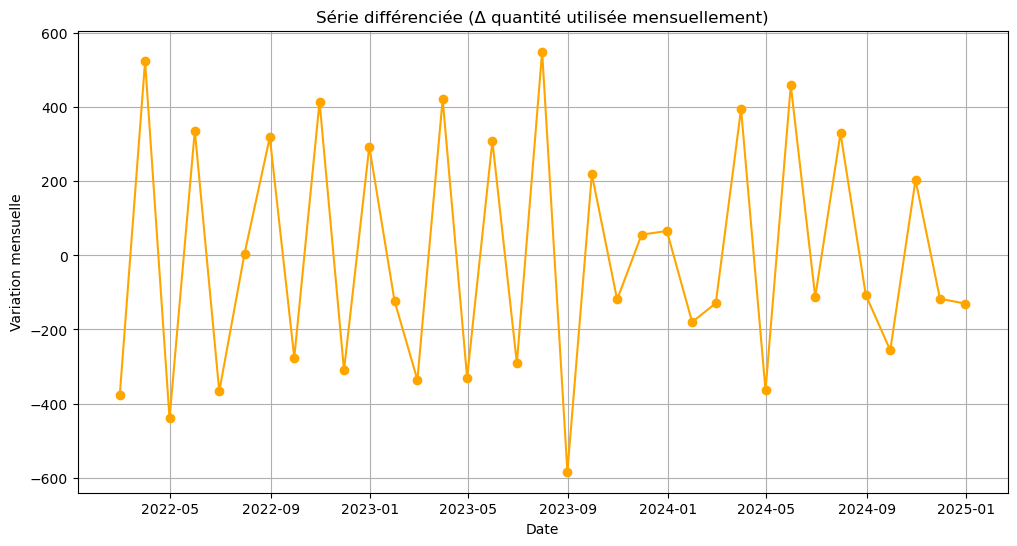

📉 Test ADF après différenciation :
Statistique ADF : -6.9505549451061475
p-value : 9.717734705932016e-10
Nombre de lags : 1
Nombre d'observations utilisées : 33
Valeurs critiques :
   1% : -3.6461350877925254
   5% : -2.954126991123355
   10% : -2.6159676124885216
✅ La série différenciée est stationnaire (rejet de H0).


In [33]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# ✅ Série initiale
series = df_monthly.copy()

# ✅ Différenciation d'ordre 1
series_diff = series.diff().dropna()

# ✅ Affichage de la série différenciée
plt.figure(figsize=(12, 6))
plt.plot(series_diff.index, series_diff.values, marker='o', color='orange')
plt.title("Série différenciée (Δ quantité utilisée mensuellement)")
plt.xlabel("Date")
plt.ylabel("Variation mensuelle")
plt.grid(True)
plt.show()

# ✅ Test ADF sur la série différenciée
if series_diff.nunique() == 1 or series_diff.empty:
    print("⚠️ Série différenciée vide ou constante. Impossible de faire le test ADF.")
else:
    result = adfuller(series_diff.values)
    print("📉 Test ADF après différenciation :")
    print(f"Statistique ADF : {result[0]}")
    print(f"p-value : {result[1]}")
    print(f"Nombre de lags : {result[2]}")
    print(f"Nombre d'observations utilisées : {result[3]}")
    print("Valeurs critiques :")
    for key, value in result[4].items():
        print(f"   {key} : {value}")
    
    if result[1] <= 0.05:
        print("✅ La série différenciée est stationnaire (rejet de H0).")
    else:
        print("❌ La série différenciée n'est PAS stationnaire (on ne rejette pas H0).")


In [34]:
pip install pmdarima


Note: you may need to restart the kernel to use updated packages.


C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will b

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=506.455, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=472.707, Time=0.02 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.04 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=504.455, Time=0.00 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=472.237, Time=0.03 sec
 ARIMA(3,1,0)(0,0,0)[0] intercept   : AIC=473.955, Time=0.04 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=473.263, Time=0.08 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=472.536, Time=0.04 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.12 sec
 ARIMA(2,1,0)(0,0,0)[0]             : AIC=470.474, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[0]             : AIC=470.829, Time=0.01 sec
 ARIMA(3,1,0)(0,0,0)[0]             : AIC=472.142, Time=0.03 sec


C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will b

 ARIMA(2,1,1)(0,0,0)[0]             : AIC=471.447, Time=0.04 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=470.822, Time=0.03 sec
 ARIMA(3,1,1)(0,0,0)[0]             : AIC=473.444, Time=0.07 sec

Best model:  ARIMA(2,1,0)(0,0,0)[0]          
Total fit time: 0.579 seconds


C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\ayadi\anaconda3\anaconda\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


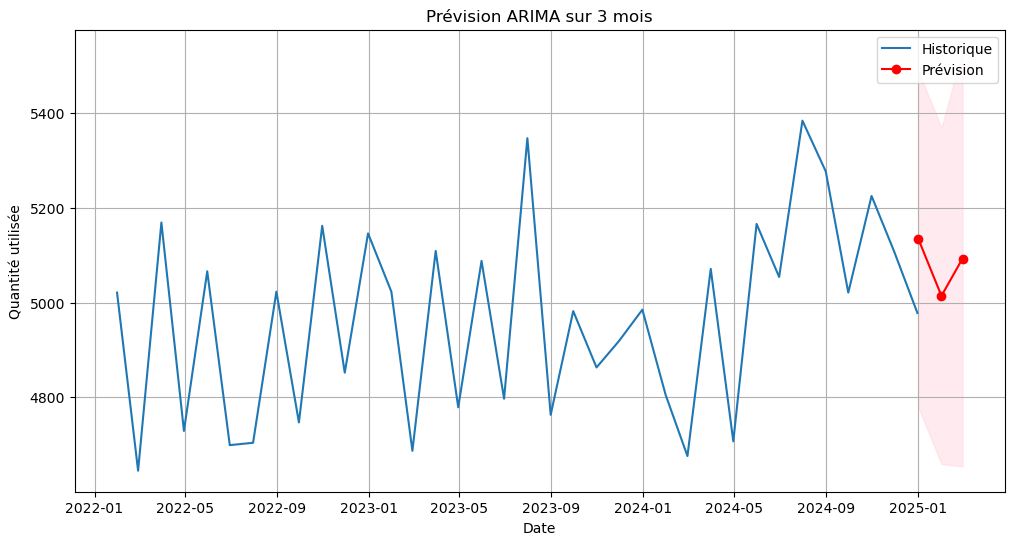

📅 Prédictions corrigées (final) :
2025-01-01    5135.162286
2025-02-01    5014.134339
2025-03-01    5092.839590
Freq: MS, dtype: float64


In [38]:
import numpy as np

# ✅ Conversion sécurisée en numpy array sans index
series_clean = df_monthly.astype(float).values

# ✅ Reconstruire le modèle ARIMA
model = pm.auto_arima(series_clean,
                      start_p=0, start_q=0,
                      max_p=5, max_q=5,
                      d=1,
                      seasonal=False,
                      trace=True,
                      error_action='ignore',
                      suppress_warnings=True,
                      stepwise=True)

# ✅ Prédiction
n_periods = 3
forecast, conf_int = model.predict(n_periods=n_periods, return_conf_int=True)

# ✅ Reconstruction de la série temporelle prévisionnelle avec index
last_date = df_monthly.index[-1]
future_dates = pd.date_range(start=last_date + pd.offsets.MonthBegin(1), periods=n_periods, freq='MS')
forecast_series = pd.Series(forecast, index=future_dates)

# ✅ Visualisation
plt.figure(figsize=(12, 6))
plt.plot(df_monthly, label="Historique")
plt.plot(forecast_series, label="Prévision", color='red', marker='o')
plt.fill_between(future_dates, conf_int[:, 0], conf_int[:, 1], color='pink', alpha=0.3)
plt.title("Prévision ARIMA sur 3 mois")
plt.xlabel("Date")
plt.ylabel("Quantité utilisée")
plt.legend()
plt.grid(True)
plt.show()

# ✅ Affichage des valeurs réelles
print("📅 Prédictions corrigées (final) :")
print(forecast_series)
